---
## Step 0 — Imports

In [17]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import os
import scipy.io
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sc.settings.verbosity = 2  # show INFO messages from scanpy
sc.settings.set_figure_params(dpi=100, facecolor="white")

print(f"scanpy  version: {sc.__version__}")
print(f"anndata version: {ad.__version__}")
print(f"pandas  version: {pd.__version__}")
print(f"numpy   version: {np.__version__}")

from besca_sc import filter_cells_and_genes, subset_adata, qc
from besca_sc import get_threshold, calculate_thresholds
from besca_sc import plot_thresholds
from besca_sc.paths import (
    EXTERNAL_DIR,
    INTERIM_DIR,
    PROCESSED_DIR,
    RAW_DIR,
    RESULTS_DIR,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
scanpy  version: 1.12.4
anndata version: 0.13.4
pandas  version: 3.0.6
numpy   version: 2.5.4


/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_46296/3760991807.py:15: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=100, facecolor="white")
/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_46296/3760991807.py:17: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(f"scanpy  version: {sc.__version__}")
/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_46296/3760991807.py:18: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(f"anndata version: {ad.__version__}")


In [18]:
SAMPLE_KEY = "ID"

---
## Step 1 — Load the merged AnnData

In [19]:
adata = sc.read_h5ad(f"{PROCESSED_DIR}/merged.h5ad")
print(adata)
print(f"\n{adata.n_obs} cells  x  {adata.n_vars} genes")

AnnData object with n_obs × n_vars = 28821 × 38606
    obs: 'htodemux_Assignment', 'multiseq_Assignment', 'hasheddrops_Assignment', 'gmmdemux_Assignment', 'hashsolo_Assignment', 'bff_consensuscall_Assignment', 'demuxmix_Assignment', 'Consensus_Assignment', 'Confidence', 'Consensus_DropletType', 'Donor', 'stimulation', 'library', 'sample_id'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

28821 cells  x  38606 genes


---
## Step 2 — Flag mitochondrial genes and calculate QC metrics

In [20]:
adata = qc(
    adata,
    mitochondrial_prefixes=("MT-", "mt-"),
    ribosomal_prefixes=("RPS", "RPL", "Rps", "Rpl"),
)

2026-10-18 16:36:16.442 | INFO     | besca_sc.pp._qc:qc:94 - calculated QC metrics for 28821 cells and 38606 genes (13 mitochondrial, 107 ribosomal); added logit_mt_fraction


---
## Step 3 — Visualise QC distributions

In [21]:
# Define initial QC thresholds for filtering cells and genes
min_genes = 200
min_cells = 3

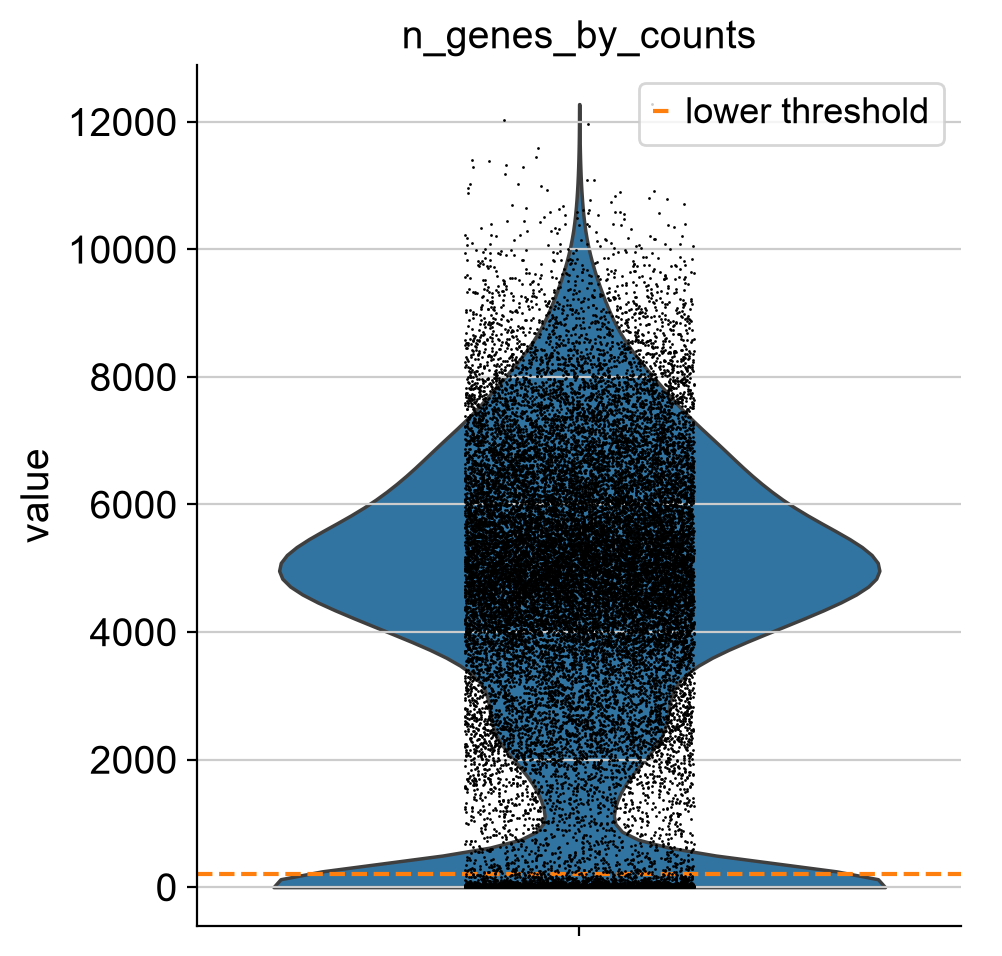

In [22]:
fig, axes = plot_thresholds(
    adata,
    thresholds={
        "n_genes_by_counts": (min_genes, None),
    }
)

---
## Step 4 — Light weight initial QC

In [23]:
sc.pp.filter_cells(adata, min_genes = min_genes)
sc.pp.filter_genes(adata, min_cells = min_cells)

filtered out 5028 cells that have less than 200 genes expressed
filtered out 6293 genes that are detected in less than 3 cells


---
## Step 5 — Save

Before saving, we copy the current counts into a dedicated layer called `counts`.  
This preserves the original values so that downstream tools (e.g. doublet detection) always have access to unmodified counts

In [24]:
adata.layers["counts"] = adata.X.copy()
print(f"Layers available: {list(adata.layers.keys())}")

Layers available: [None, 'counts']


In [25]:
out_path = f"{PROCESSED_DIR}/initial_qc_merged.h5ad"
adata.write_h5ad(out_path)
print(f"Saved: {out_path}")
print(f"  {adata.n_obs} cells  x  {adata.n_vars} genes")
print(f"  Layers: {list(adata.layers.keys())}")

Saved: /Users/adaml9/besca_sc/data/processed/initial_qc_merged.h5ad
  23793 cells  x  32313 genes
  Layers: [None, 'counts']
